# ۱۰ - تحلیل عملکرد فروشندگان

پاسخ به سؤال‌های بخش ۱۲ صورت‌مسئله: تعداد فروشندگان، توزیع جغرافیایی، فروش، تمرکز و رضایت مشتری.

## ۲. سؤال‌های کسب‌وکاری

1. چند فروشنده فعال است و در کدام ایالت‌ها هستند؟
2. ده فروشنده برتر بر اساس مبلغ فروش کدام‌اند؟
3. سهم ده فروشنده اول از کل فروش چقدر است؟
4. آیا رتبه‌بندی حجم و مبلغ یکسان است؟
5. کدام فروشندگان پرفروش امتیاز پایین دارند؟

## ۱. عنوان و هدف

پاسخ به سؤال‌های بخش ۱۲ صورت‌مسئله: تعداد فروشندگان، توزیع جغرافیایی، فروش، تمرکز و رضایت مشتری.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

مبنای محاسبه، جدول «یک ردیف برای هر زوج سفارش-فروشنده» است تا امتیاز یک سفارش که چند فروشنده دارد، چند بار شمرده نشود. دسته‌بندی فروشندگان با حداقل ۳۰ نظر برای مقایسه امتیاز کافی در نظر گرفته می‌شود.

## ۶. تحلیل عددی

### ۱۲.۱ تعداد و پراکندگی فروشندگان

In [2]:
display(pd.Series(M.seller_overview(ds), name="value"))

n_sellers                       3.095000e+03
n_states                        2.300000e+01
median_items_per_seller         8.000000e+00
median_revenue_per_seller       8.214800e+02
total_revenue                   1.359164e+07
top10_revenue                   1.787242e+06
top10_revenue_share_pct         1.314960e+01
top10_items_share_pct           1.020150e+01
sellers_with_min_reviews        6.280000e+02
sellers_pct_with_min_reviews    2.029080e+01
Name: value, dtype: float64

In [3]:
display(M.sellers_by_state(ds).head(10))

,seller_state,n_sellers,pct_sellers,rank
0,SP,1849,59.7415,1
1,PR,349,11.2763,2
2,MG,244,7.8837,3
3,SC,190,6.1389,4
4,RJ,171,5.5250,5
5,RS,129,4.1680,6
6,GO,40,1.2924,7
7,DF,30,0.9693,8
8,ES,23,0.7431,9
9,BA,19,0.6139,10


### ۱۲.۲ و ۱۲.۴ فروشندگان برتر و تمرکز فروش

In [4]:
display(M.top_sellers(ds, "revenue", 10)[["seller_id", "seller_state", "n_items", "n_orders", "revenue", "revenue_share_pct", "n_reviews", "mean_score"]])

,seller_id,seller_state,n_items,n_orders,revenue,revenue_share_pct,n_reviews,mean_score
0,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1156,1132,229472.63,1.6883,1124,4.13
1,53243585a1d6dc2643021fd1853d8905,BA,410,358,222776.05,1.6391,356,4.13
2,4a3ca9315b744ce9f8e9374361493884,SP,1987,1806,200472.92,1.4750,1785,3.83
3,fa1c13f2614d7b5c4749cbc52fecda94,SP,586,585,194042.03,1.4277,581,4.34
4,7c67e1448b00f6e969d365cea6b010ab,SP,1364,982,187923.89,1.3826,976,3.49
5,7e93a43ef30c4f03f38b393420bc753a,SP,340,336,176431.87,1.2981,335,4.21
6,da8622b14eb17ae2831f4ac5b9dab84a,SP,1551,1314,160236.57,1.1789,1308,4.18
7,7a67c85e85bb2ce8582c35f2203ad736,SP,1171,1160,141745.53,1.0429,1151,4.25
8,1025f0e2d44d7041d6cf58b6550e0bfa,SP,1428,915,138968.55,1.0225,907,3.99
9,955fee9216a65b617aa5c0531780ce60,SP,1499,1287,135171.70,0.9945,1277,4.16


### ۱۲.۵ و ۱۲.۶ فروش بالا با امتیاز پایین

In [5]:
candidates, threshold = M.high_revenue_low_rating_sellers(ds)
print(f"آستانه مبلغ فروش: {threshold:,.2f} رئال")
display(candidates[["seller_id", "seller_state", "n_items", "n_orders", "revenue", "n_reviews", "mean_score", "score_vs_overall"]])

آستانه مبلغ فروش: 9,525.32 رئال


,seller_id,seller_state,n_items,n_orders,revenue,n_reviews,mean_score,score_vs_overall
0,7c67e1448b00f6e969d365cea6b010ab,SP,1364,982,187923.89,976,3.49,-0.60
1,2eb70248d66e0e3ef83659f71b244378,SP,212,202,42628.61,198,2.70,-1.39
2,712e6ed8aa4aa1fa65dab41fed5737e4,SC,87,79,39815.00,78,3.38,-0.70
3,88460e8ebdecbfecb5f9601833981930,PR,302,248,31546.55,247,3.41,-0.67
4,710e3548e02bc1d2831dfc4f1b5b14d4,PR,142,136,23979.11,135,3.36,-0.72
5,8444e55c1f13cd5c179851e5ca5ebd00,MG,109,99,22873.21,99,3.26,-0.82
6,8e6d7754bc7e0f22c96d255ebda59eba,SP,130,85,14497.27,85,3.58,-0.51
7,0b35c634521043bf4b47e21547b99ab5,PR,78,51,13533.65,50,3.36,-0.73
8,1ca7077d890b907f89be8c954a02686a,SP,137,115,13341.57,114,2.33,-1.75
9,c60b801f2d52c7f7f91de00870882a75,SP,41,41,12913.50,41,3.32,-0.77


## ۷. نمودارها

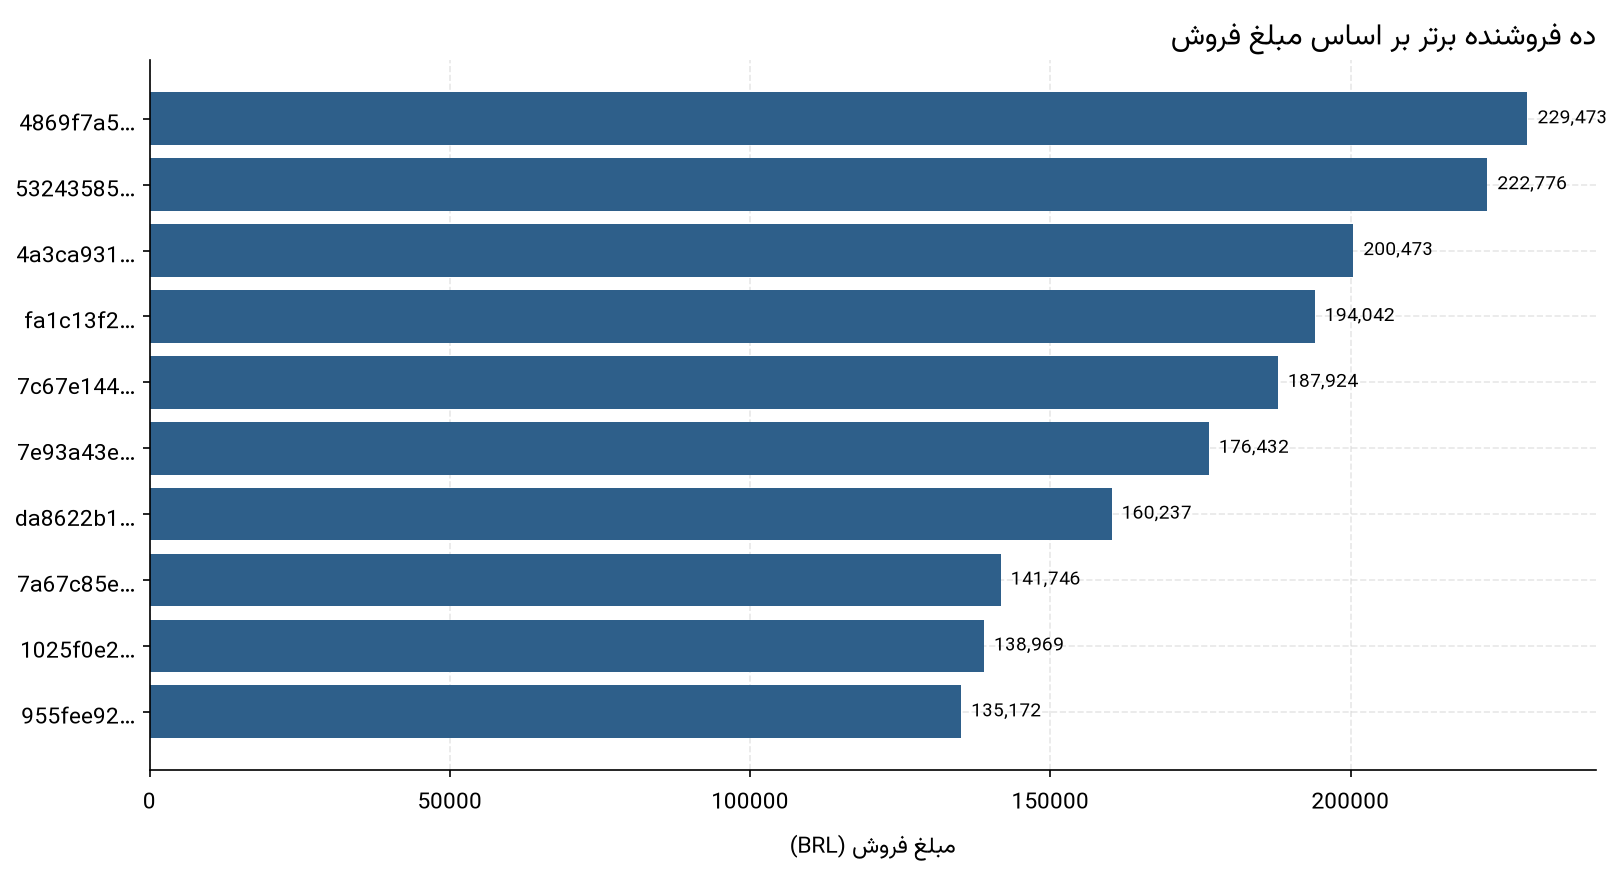

نمودار ۲۴ - ده فروشنده اول بر اساس مبلغ فروش (شناسه فروشنده کوتاه شده است)


In [6]:
display(Image(filename=str(FIGURES_DIR / "fig_24_top_sellers.png"), width=920))
caption = FIGURES_DIR / "fig_24_top_sellers.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

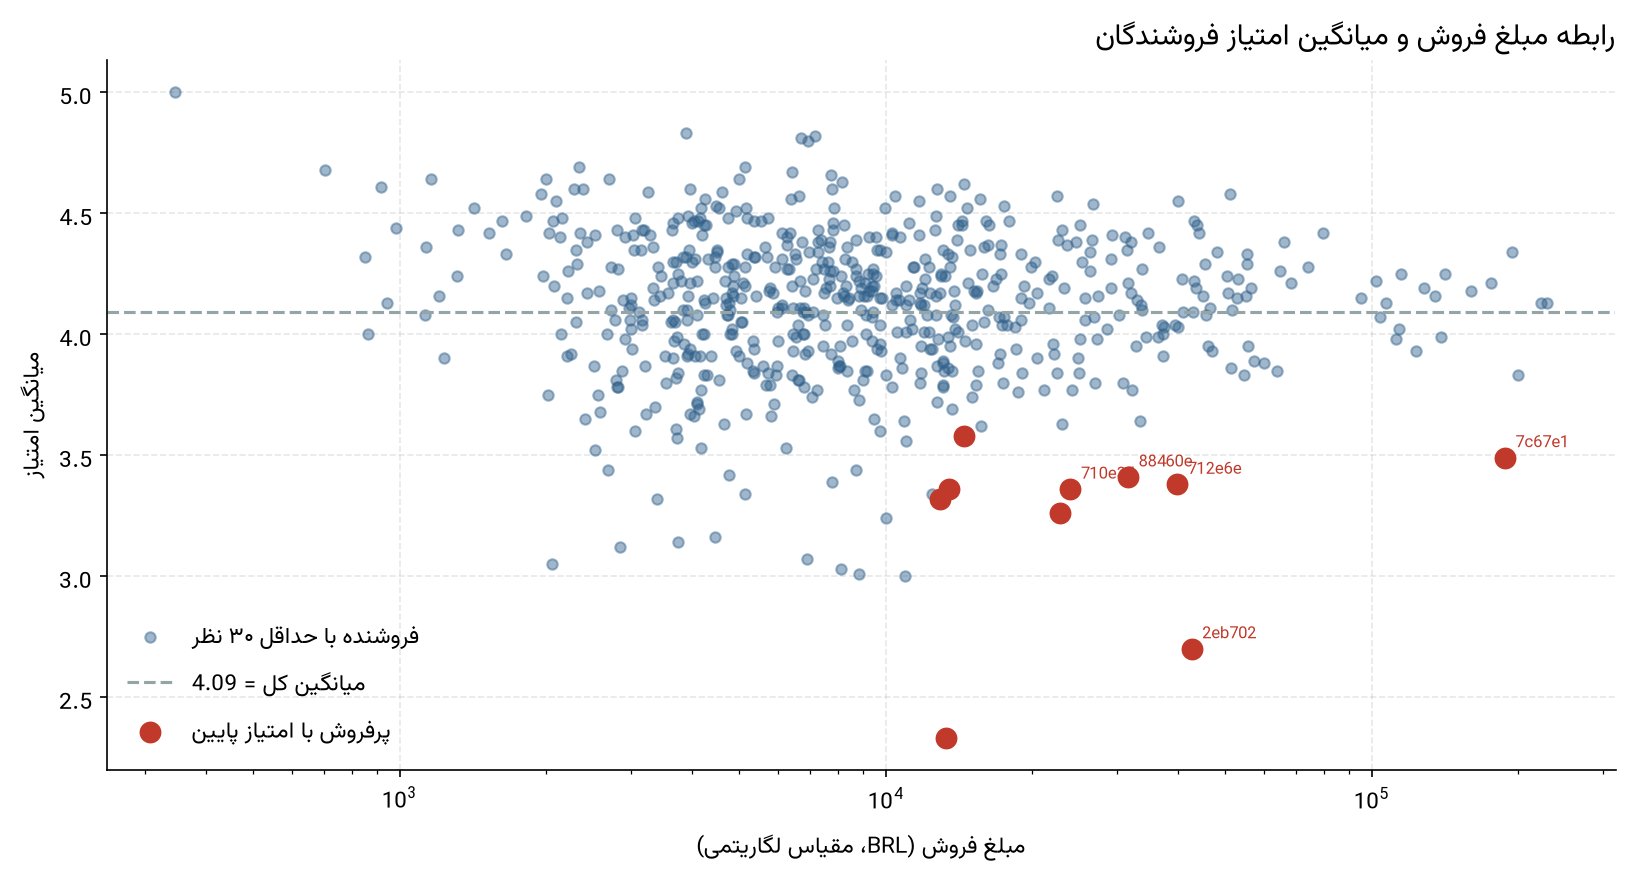

نمودار ۲۵ - فروشندگان پرفروش با امتیاز پایینتر از میانگین کل


In [7]:
display(Image(filename=str(FIGURES_DIR / "fig_25_seller_revenue_vs_score.png"), width=920))
caption = FIGURES_DIR / "fig_25_seller_revenue_vs_score.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- ۳٬۰۹۵ فروشنده یکتا در ۲۳ ایالت فعالیت دارند؛ ۱٬۸۴۹ فروشنده (۵۹.۷۴ درصد) در ایالت SP هستند.
- میانه تعداد اقلام هر فروشنده ۸ و میانه مبلغ فروش ۸۲۱.۴۸ رئال است؛ یعنی نیمی از فروشندگان بسیار کوچک‌اند.
- ده فروشنده اول ۱٬۷۸۷٬۲۴۲ رئال فروش دارند که ۱۳.۱۵ درصد کل مبلغ فروش است؛ تمرکز فروش عمدتاً در سطح دسته‌بندی است، نه فروشنده.
- فقط ۶۲۸ فروشنده (۲۰.۲۹ درصد) حداقل ۳۰ نظر دارند و برای مقایسه امتیاز قابل اتکا هستند.
- ۱۰ فروشنده پرفروش با امتیاز پایین‌تر از میانگین کل شناسایی شد؛ شاخص‌ترین مورد فروشنده `7c67e144…` با ۱۸۷٬۹۲۴ رئال فروش، ۹۷۶ نظر و میانگین امتیاز ۳.۴۹ (۰.۶۰ کمتر از میانگین کل) است.

## ۹. تفسیر کسب‌وکاری

خطر وابستگی به تعداد کم فروشنده کم‌تر از حد انتظار است، اما کیفیت در بخشی از فروشندگان بزرگ پایین است. اختلاف رتبه حجم و مبلغ در میان فروشندگان نیز نشان می‌دهد فروشندگان کم‌حجم اما گران‌قیمت، سهم ارزشی مهمی دارند.

## ۱۰. محدودیت‌های تحلیل

اکثر فروشندگان نمونه نظر کافی ندارند؛ امتیاز آنان برای قضاوت قابل استفاده نیست. داده شامل مدت همکاری فروشنده، نرخ لغو سفارش یا اطلاعات قراردادی نیست.

## ۱۱. نتیجه‌گیری

بازار فروشندگان گسترده اما نامتوازن است؛ پایش فروشندگان پرفروش با امتیاز پایین می‌تواند ریسک اعتباری را کاهش دهد.